[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsheese/cs377/blob/main/supplemental/Nested_CV_Review.ipynb)

# Nested CV Review (with Ridge and Lasso thrown in):
Follow-up to the Nested CV pair activity (17_2_1_4 Tuning, 17_2_1_5 Nested CV)**

This notebook goes back over the Nested CV pair activity. Most pairs got the numbers right. Almost everyone found the 11,763 test MAE in Q3 and the 12,806 and 12,747 MAEs in Q4. Where answers went wrong was mostly in the explanations, and several of the same mistakes showed up in more than one pair. This notebook works through each of those mistakes in writing, with code you can run to check the reasoning for yourself. It is for review only, and there is nothing to turn in, and it presents no new concepts or information.

The sections follow the quiz questions:

1. Why Lasso can leave a feature at exactly zero (Q1)
2. How many houses each loop uses (Q2)
3. Where the `regressor` in `'regressor__alpha'` comes from (Q3)
4. Reading the five fold alphas (Q4)
5. Luck, not leakage: why one test split misled us (Q5)
6. What to deploy, and which number to report (Q6)

The Setup cell builds the same variables as the one in the pair notebook (it also loads seaborn for the plots), so `X_train`, `X_test`, `X`, `y`, `ALPHAS`, `make_pipe` and `dollars` mean exactly what they meant in the paired activity.

The notebook is saved with its outputs, so you can read it without running anything. But, as I've mentioned before, messing with the code and running it is a good way to check your understanding.

## Setup

In [ ]:
import warnings
warnings.filterwarnings('ignore')   # Lasso prints convergence warnings for small alphas

import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import (GridSearchCV, KFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.metrics import mean_absolute_error

# the Ames data, cleaned exactly as in 17_2_1_1 (same split as 17_2_1_4)
module_url = "https://raw.githubusercontent.com/bsheese/cs377/main/17_regression_crossval/17_2_1_MLR/ames_cleaning.py"
urllib.request.urlretrieve(module_url, "ames_cleaning.py")
from ames_cleaning import load_and_clean_ames

data_url = "https://raw.githubusercontent.com/bsheese/cs377/main/data/data_housing_ames.txt"
X_train, X_test, y_train, y_test = load_and_clean_ames(data_url)   # y is log sale price

# all 2,925 houses, for nested CV (as in 17_2_1_5)
X = pd.concat([X_train, X_test])
y = pd.concat([y_train, y_test])

ALPHAS = np.logspace(-2, 4, 20)          # 20 Ridge alphas from 0.01 to 10,000


def make_pipe(model):
    """StandardScaler, then the model, in a step named 'regressor' (the same pipeline as 17_2_1_4)."""
    return Pipeline([('scaler', StandardScaler()), ('regressor', model)])


def dollars(y_true, y_pred):
    """Mean absolute error in dollars, from log-price values."""
    return mean_absolute_error(np.exp(y_true), np.exp(y_pred))


print("training houses:", len(X_train), "  test houses:", len(X_test), "  all houses:", len(X),
      "  features:", X.shape[1])

training houses: 2340   test houses: 585   all houses: 2925   features: 225


## 1. Why Lasso can leave a feature at exactly zero (Q1)

Q1 was the recap from the Ridge vs. Lasso activity, and the same idea is on the upcoming exam. Every pair worked out the two taxes in part (a): moving the coefficient *b* from 0 to 0.1 adds 0.1² = 0.01 of tax under Ridge and |0.1| = 0.1 under Lasso. Part (b) asked you to **use those numbers** to explain why Lasso can stop at exactly zero while Ridge always moves at least a little, and no pair made that argument. Most answers restated the fact ("Lasso removes weak features, Ridge only shrinks them"), which is what the question asked you to explain. Others described the penalties in ways that are not how they work, for example that Ridge "divides" so it can only get close to zero, or that Lasso's push gets stronger near zero (it stays the same size).

The argument is a comparison between what a step gains and what it costs. Each model picks *b* to make the total cost as small as possible:

**total cost = misfit + α × tax**

In this question the misfit is (*z* - *b*)², the squared distance between the coefficient and its OLS value *z* = 0.4, and α = 1. With *b* = 0 the misfit is 0.4² = 0.16, and with *b* = 0.1 it is 0.3² = 0.09, which are the numbers in the question. A model takes the step only if the misfit goes down by more than α × tax goes up. The cell below adds up both totals at *b* = 0 and *b* = 0.1.

In [ ]:
z, alpha = 0.4, 1

rows = []
for b in [0, 0.1]:
    misfit = (z - b) ** 2
    rows.append({'b': b, 'misfit': misfit,
                 'Ridge tax (b²)': b ** 2, 'Ridge total': misfit + alpha * b ** 2,
                 'Lasso tax (|b|)': abs(b), 'Lasso total': misfit + alpha * abs(b)})
pd.DataFrame(rows).round(3)

,b,misfit,Ridge tax (b²),Ridge total,Lasso tax (|b|),Lasso total
0,0.0,0.16,0.00,0.16,0.0,0.16
1,0.1,0.09,0.01,0.10,0.1,0.19


Read the two "total" columns from the first row to the second. Ridge's total goes down, from 0.16 to 0.10: the step saves 0.07 of misfit and costs only 0.01 of tax, so Ridge takes it. Lasso's total goes **up**, from 0.16 to 0.19: the step saves the same 0.07 but costs 0.1, so Lasso is better off staying at *b* = 0. That comparison (0.07 saved against 0.01 or 0.1 paid) answers part (a). Part (b) asks why the comparison always favors a step under Ridge but can go against one under Lasso, and the way to see that is to look at what happens to each tax as the step gets smaller. A step of size *s* away from zero costs *s*² under Ridge, and *s*² shrinks much faster than *s* does: a step of 0.01 costs only 0.0001. The misfit that a small step saves shrinks only in proportion to *s* (it is about 2 × *z* × *s*). So for a small enough step, Ridge's tax is always smaller than the misfit it saves, as long as *z* is not exactly zero, and Ridge always moves at least a little. Lasso's tax for the same step is *s*, which shrinks at the same rate as the saving. The step pays off only if 2 × *z* × *s* is bigger than α × *s*, which means only if *z* is bigger than α / 2. Here *z* = 0.4 and α / 2 = 0.5, so no step away from zero pays off, no matter how small. The cell below checks this for three step sizes.

___

Still confused? Let me try it a different way:

**Part (a)**
Comparing the "total" columns between the first and second rows:

* **Ridge:** The total cost decreases from 0.16 to 0.10. Taking the step saves 0.07 in misfit while incurring only 0.01 in penalty, so Ridge takes the step.
* **Lasso:** The total cost increases from 0.16 to 0.19. The step saves the same 0.07 in misfit but incurs a 0.10 penalty, so Lasso is better off remaining at $b = 0$.

Comparing the 0.07 misfit reduction against the penalty incurred (0.01 vs. 0.10) answers part (a).

**Part (b)**
Part (b) asks why taking a step always favors Ridge but can work against Lasso. The key is evaluating how each penalty behaves as the step size $s$ approaches zero:

* **Ridge ($L_2$ penalty):** A step of size $s$ away from zero incurs a penalty of $s^2$, which shrinks much faster than $s$ itself (e.g., $s = 0.01$ costs only $0.0001$). Meanwhile, the misfit reduction shrinks linearly with $s$ (approximately $2zs$). Because $s^2$ shrinks faster than $s$, Ridge's penalty will always be smaller than the misfit saved for a sufficiently small step (as long as $z \neq 0$). Consequently, Ridge always moves at least a little.
* **Lasso ($L_1$ penalty):** A step of size $s$ incurs a penalty proportional to $s$ ($\alpha s$), which shrinks at the exact same rate as the misfit reduction ($2zs$). A step only pays off if $2zs > \alpha s$, or equivalently if $z > \alpha / 2$. Here, $z = 0.4$ and $\alpha / 2 = 0.5$. Because $z < \alpha / 2$, no step away from zero pays off, regardless of how small $s$ is.

The cell below checks this behavior across three step sizes.

In [ ]:
rows = []
for s in [0.1, 0.01, 0.001]:
    rows.append({'step s': s,
                 'misfit saved': z ** 2 - (z - s) ** 2,
                 'Ridge tax (s²)': alpha * s ** 2,
                 'Lasso tax (s)': alpha * s})
steps = pd.DataFrame(rows)
steps['Ridge steps?'] = steps['misfit saved'] > steps['Ridge tax (s²)']
steps['Lasso steps?'] = steps['misfit saved'] > steps['Lasso tax (s)']
steps

,step s,misfit saved,Ridge tax (s²),Lasso tax (s),Ridge steps?,Lasso steps?
0,0.100,0.070000,0.010000,0.100,True,False
1,0.010,0.007900,0.000100,0.010,True,False
2,0.001,0.000799,0.000001,0.001,True,False


For every step size, the misfit saved is a bit less than 0.8 × *s* (0.07 for a step of 0.1, 0.0079 for 0.01, 0.0008 for 0.001). Ridge's tax falls far below that as the step shrinks (0.01, then 0.0001, then 0.000001), so Ridge takes every step. Lasso's tax is the step size itself (0.1, 0.01, 0.001), which is always more than the misfit saved, so Lasso turns down every step and the coefficient stays at exactly zero.

The same thing is visible if you plot each model's total cost for every *b* between 0 and the OLS value 0.4.

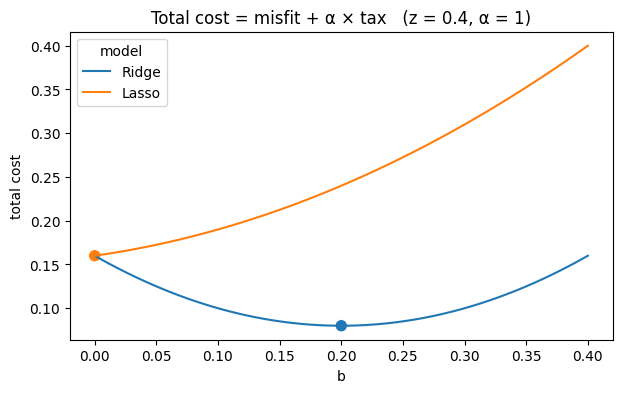

,b,total cost,model
81,0.0,0.16,Lasso
40,0.2,0.08,Ridge


In [ ]:
b_grid = np.linspace(0, z, 81)
curves = pd.concat([
    pd.DataFrame({'b': b_grid, 'total cost': (z - b_grid) ** 2 + alpha * b_grid ** 2, 'model': 'Ridge'}),
    pd.DataFrame({'b': b_grid, 'total cost': (z - b_grid) ** 2 + alpha * np.abs(b_grid), 'model': 'Lasso'}),
], ignore_index=True)
best = curves.loc[curves.groupby('model')['total cost'].idxmin()]

plt.figure(figsize=(7, 4))
sns.lineplot(data=curves, x='b', y='total cost', hue='model', hue_order=['Ridge', 'Lasso'])
sns.scatterplot(data=best, x='b', y='total cost', hue='model', hue_order=['Ridge', 'Lasso'], s=80, legend=False)
plt.title('Total cost = misfit + α × tax   (z = 0.4, α = 1)')
plt.show()
best

The dots mark each model's lowest point. Ridge's curve bottoms out at *b* = 0.2, halfway between zero and the OLS value of 0.4, so Ridge shrinks the coefficient without removing it. Lasso's curve is lowest at *b* = 0 and climbs from the very start. Its slope at zero is uphill because the tax adds 1 to the slope while the misfit takes away only 2 × 0.4 = 0.8.

Part (c) asked how many of the 225 coefficients Ridge keeps nonzero at α = 10, 100 and 1,000. Four pairs answered it correctly, and one pair wrote instead about which α Ridge would choose. The answer follows from part (b): Ridge never sets a coefficient exactly to zero, so it keeps all 225 at every α. The cell below checks it on the training set, next to the Lasso counts quoted in the question.

In [ ]:
for name, model in [('Ridge', Ridge(alpha=10)), ('Ridge', Ridge(alpha=100)), ('Ridge', Ridge(alpha=1000)),
                    ('Lasso', Lasso(alpha=0.001, max_iter=10000)), ('Lasso', Lasso(alpha=0.005, max_iter=10000)),
                    ('Lasso', Lasso(alpha=0.02, max_iter=10000)), ('Lasso', Lasso(alpha=0.1, max_iter=10000))]:
    coef = make_pipe(model).fit(X_train, y_train).named_steps['regressor'].coef_
    print(f"{name} alpha = {model.alpha:<6g}  nonzero coefficients: {(coef != 0).sum()} of {len(coef)}")

Ridge alpha = 10      nonzero coefficients: 225 of 225
Ridge alpha = 100     nonzero coefficients: 225 of 225
Ridge alpha = 1000    nonzero coefficients: 225 of 225
Lasso alpha = 0.001   nonzero coefficients: 151 of 225
Lasso alpha = 0.005   nonzero coefficients: 66 of 225


Lasso alpha = 0.02    nonzero coefficients: 26 of 225
Lasso alpha = 0.1     nonzero coefficients: 6 of 225


Ridge keeps all 225 coefficients at all three alphas. At α = 1,000 the coefficients are shrunk more overall than at α = 10, but none of them is set to zero. (Not every single coefficient gets smaller as α grows: when features are correlated, Ridge can shift weight from one to another, so a few coefficients grow or even change sign. What shrinks is the set of coefficients as a whole.) Lasso keeps 151, 66, 26 and then only 6 as its α grows from 0.001 to 0.1. (Lasso's α values are much smaller than Ridge's because scikit-learn scales the error term differently in the two models (Lasso divides the sum of squared errors by 2 × the number of houses, and Ridge does not), so compare α values within one model, not across the two.)

## 2. How many houses each loop uses (Q2)

Every pair had the outer loop right: each outer fold holds out 2,925 / 5 = 585 houses and hands the other 2,340 to the inner loop. Two pairs then said that each inner fit trains on 468 houses. 468 is the size of one **inner fold**, the slice that the inner loop holds out to score each α. The inner loop cuts the 2,340 houses into 5 folds of 468, trains on four of them and scores on the fifth, so each inner fit trains on 4 × 468 = 1,872 houses.

The cell below builds the same folds that `cv=5` builds. (For a regression model, `cv=5` means `KFold(5)` without shuffling, so these are exactly the folds the pair notebook used.) It counts the houses in the first outer fold and in each of the five inner folds inside it.

In [ ]:
outer = KFold(5)
outer_train, outer_test = next(outer.split(X))
print(f"outer fold 1: hold out {len(outer_test)} houses, hand {len(outer_train)} to the inner loop")

inner_folds = KFold(5)
for i, (inner_train, inner_val) in enumerate(inner_folds.split(outer_train), start=1):
    print(f"   inner fold {i}: train on {len(inner_train)} houses, score each alpha on {len(inner_val)}")

outer fold 1: hold out 585 houses, hand 2340 to the inner loop
   inner fold 1: train on 1872 houses, score each alpha on 468
   inner fold 2: train on 1872 houses, score each alpha on 468
   inner fold 3: train on 1872 houses, score each alpha on 468
   inner fold 4: train on 1872 houses, score each alpha on 468
   inner fold 5: train on 1872 houses, score each alpha on 468


The first outer fold holds out 585 houses and hands 2,340 to the inner loop. Inside it, each of the five inner fits trains on 1,872 houses and scores each α on the remaining 468. The other four outer folds have the same sizes.

Part (b) asked why the inner loop never seeing the outer fold's 585 houses makes the final error honest. Most pairs answered this well. The 585 held-out houses play no part in choosing α or fitting the coefficients, so when the tuned model is scored on them, they are as new to it as houses it would meet after deployment. One pair said the reason was that it "prevents lucky splits." That is a real benefit of nested CV, but it comes from scoring on five folds instead of one (section 5), not from keeping the inner loop away from the outer fold.

## 3. Where the `regressor` in `'regressor__alpha'` comes from (Q3)

Every pair that answered Q3 fixed the error and found the test MAE of $11,763, and all but one also reported the winning α of 61.6. Two parts of the explanation were shaky: why the grid key needs the `regressor__` prefix, and what would change if the pipeline step had a different name.

`GridSearchCV` tunes whatever estimator you give it, and here that is the whole pipeline, not the Ridge model inside it. A pipeline has no `alpha` of its own. It gives each of its steps' parameters a name made of the step name, two underscores and the parameter name. You can ask a pipeline for that list directly.

In [ ]:
print([key for key in make_pipe(Ridge()).get_params() if 'alpha' in key])

renamed = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
print([key for key in renamed.get_params() if 'alpha' in key])

['regressor__alpha']
['model__alpha']


The pipeline from `make_pipe` calls Ridge's penalty `regressor__alpha`, because the Ridge step is named `'regressor'`. In the renamed pipeline, the same parameter is called `model__alpha`. So if the step were named `'model'`, the grid key would have to become `'model__alpha'` (not `'model__regressor'`), and so would every other place that names the step, such as `best_params_['regressor__alpha']` or `named_steps['regressor']`.

## 4. Reading the five fold alphas (Q4)

Two things in Q4 tripped up several pairs.

- **The untuned run has no list of alphas.** It hands `cross_val_predict` a plain Ridge pipeline, which uses scikit-learn's default α = 1 in every fold. The five alphas the cell prints come from the `cross_validate(inner, ...)` line near the bottom of the cell, which runs the grid search inside each outer fold. Two pairs wrote the same five alphas under both runs.
- **Tuning saved 59 dollars per house, not 59 houses.** The MAE is an average error in dollars, so going from 12,806 dollars to 12,747 dollars means the tuned model's price predictions are off by 59 dollars less on average.

The question also asked why the folds can choose different alphas and what it means that they are close. To answer the second part you need to compare the chosen alphas with the grid they were chosen from, which is the step most answers skipped. The cell below runs both versions and then marks the chosen alphas in the grid.

In [ ]:
inner = GridSearchCV(make_pipe(Ridge()), {'regressor__alpha': ALPHAS},
                     cv=5, scoring='neg_mean_squared_error')

untuned_mae = dollars(y, cross_val_predict(make_pipe(Ridge()), X, y, cv=5))
nested_mae = dollars(y, cross_val_predict(inner, X, y, cv=5))
print(f"untuned (alpha = 1 in every fold): ${untuned_mae:,.0f}")
print(f"nested (each fold tunes alpha):    ${nested_mae:,.0f}")
print(f"tuning saved:                      ${untuned_mae - nested_mae:,.0f} per house")

folds = cross_validate(inner, X, y, cv=5, return_estimator=True)
fold_alphas = [float(g.best_params_['regressor__alpha']) for g in folds['estimator']]
print('\nalpha chosen by each outer fold:', [round(a, 1) for a in fold_alphas])

grid_table = pd.DataFrame({'alpha': ALPHAS.round(2),
                           'times chosen': [int(sum(np.isclose(a, f) for f in fold_alphas)) for a in ALPHAS]},
                          index=range(1, len(ALPHAS) + 1))
grid_table

untuned (alpha = 1 in every fold): $12,806
nested (each fold tunes alpha):    $12,747
tuning saved:                      $59 per house



alpha chosen by each outer fold: [127.4, 127.4, 61.6, 127.4, 61.6]


,alpha,times chosen
1,0.01,0
2,0.02,0
3,0.04,0
4,0.09,0
5,0.18,0
6,0.38,0
7,0.78,0
8,1.62,0
9,3.36,0
10,6.95,0


The five folds chose 127.4 three times and 61.6 twice. In the grid, those are values 13 and 14 out of 20, next to each other in a list that runs from 0.01 to 10,000. Each outer fold trains on a different 80% of the houses, so its inner loop sees slightly different data and can land on a slightly different α. But all five landed on the same pair of neighboring values. That means the best amount of shrinkage does not depend much on which houses happen to be in the training data, so the tuning is stable.

The payoff from tuning is a separate point. Going from the default α = 1 (between values 7 and 8 in the grid, 0.78 and 1.62) to α values of 61.6 and 127.4 lowered the error by only 59 dollars out of about 12,800 dollars, so on this data Ridge's error changes slowly as α moves away from its best value. 17_2_1_4's section "The ROI of Hyperparameter Tuning" also found that tuning moved Ridge's error only a little, but its starting guess was α = 100, which was already between the two values chosen here. The comparison in this notebook starts from α = 1, much further from the best value, and tuning still saved only 59 dollars.

## 5. Luck, not leakage: why one test split misled us (Q5)

Q5 was the main point of the activity. A classmate said that "nested CV made the model worse," because Q3 reported 11,763 dollars and nested CV reported 12,747 dollars. Pairs disagreed with the classmate, which is right, but several of the reasons given were wrong or missed the point:

- one pair said the Q3 procedure has **leakage**;
- one pair said nested CV made the model **more accurate**;
- one pair gave the range of the **alphas** the ten splits chose, in place of the range of their test MAEs.

Start with leakage. Leakage means that information from the test data got into a choice the model made: a scaler fit on all the data, a feature picked after looking at the test rows, or an α chosen by its test score. Q3 has none of these. `GridSearchCV` chose α using only `X_train`, and `X_test` was used once, at the end, to score the result. So 11,763 dollars is an honest score. The problem with it is that it is one honest score from one particular set of 585 test houses, and a different set gives a different number. The cell below repeats the Q3 procedure (split, tune on the training houses, score on the test houses) for ten random splits.

In [ ]:
grid = GridSearchCV(make_pipe(Ridge()), {'regressor__alpha': ALPHAS},
                    cv=5, scoring='neg_mean_squared_error')
rows = []
for seed in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    grid.fit(X_tr, y_tr)
    rows.append({'split': seed, 'alpha chosen': round(float(grid.best_params_['regressor__alpha']), 1),
                 'test MAE': round(dollars(y_te, grid.predict(X_te)))})
splits = pd.DataFrame(rows)
print(f"10 test MAEs: ${splits['test MAE'].min():,} to ${splits['test MAE'].max():,}")
splits.sort_values('test MAE')

10 test MAEs: $12,411 to $14,120


,split,alpha chosen,test MAE
8,8,263.7,12411
0,0,61.6,12511
5,5,61.6,12758
7,7,61.6,12876
2,2,263.7,12926
4,4,127.4,12999
1,1,61.6,13262
9,9,127.4,13473
6,6,127.4,13719
3,3,263.7,14120


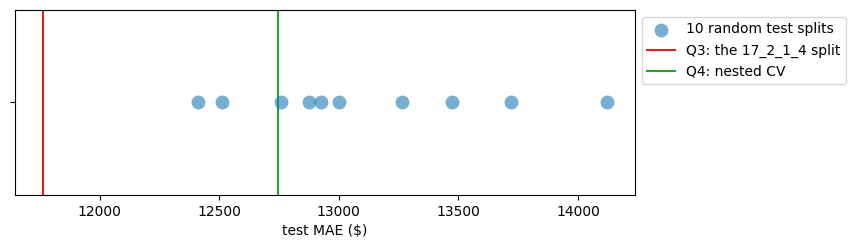

In [ ]:
q3_mae = 11763   # the 17_2_1_4 split, from Q3

plt.figure(figsize=(8, 2.4))
sns.stripplot(data=splits, x='test MAE', size=10, alpha=0.6, jitter=False, label='10 random test splits')
plt.axvline(q3_mae, color='tab:red', label='Q3: the 17_2_1_4 split')
plt.axvline(nested_mae, color='tab:green', label='Q4: nested CV')
plt.xlabel('test MAE ($)')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

The ten test MAEs run from 12,411 dollars (split 8) to 14,120 dollars (split 3), a spread of about 1,700, and the only thing that changed between them is which 585 houses ended up in the test set (and so which 2,340 were left for training). The Q3 split's 11,763 dollars (red line) is lower than all ten, so it was a favorable split: its test set happened to hold houses that were easier than usual to price. 17_2_1_4 pointed this out too, when its test MAE came out better than its cross-validation estimate. The nested 12,747 dollars (green line) sits inside the range, between the second-lowest split (12,511) and the third-lowest (12,758).

That is the reply to the classmate. Q3 and nested CV are not two different kinds of model. Both run the same procedure: tune α by 5-fold CV on the training houses, fit, then score on houses that played no part in the tuning. What differs is how much data the score is based on. Q3 scores the procedure on one set of 585 houses. Nested CV scores it on five different sets of 585 that together cover all 2,925 houses, so every house is predicted exactly once by a model that never saw it. So nested CV did not make the model worse, and it did not make it more accurate either. It gave a more reliable estimate of how well the procedure works, and that estimate is higher than the Q3 number because the Q3 split was a favorable one.

(Scoring every house is also why the nested number moves much less than a single split does when the houses are reshuffled, which is what extra credit Q8 asked about. A single split's number changes with which 585 houses land in the test set. Every reshuffled nested run scores the same 2,925 houses, so that source of variation is gone, and the only thing left to change is which training folds produced each house's prediction.)

Look also at the `alpha chosen` column. The ten splits chose 61.6, 127.4 or 263.7, three neighboring grid values, which is the same stability you saw in section 4. These are the numbers one pair reported as the range of the ten MAEs, but they are penalty strengths, not errors in dollars. And one pair answered Q6 by averaging the test MAEs of the three splits that happened to choose 127.4 (splits 4, 6 and 9: 12,999, 13,719 and 13,473, which average to 13,397). The next section explains why that average is not the number to report.

## 6. What to deploy, and which number to report (Q6)

Nested CV built five tuned models, one per outer fold. None of them is the model to deploy. Each was trained on only 80% of the houses, and their job was to measure how well the procedure works, not to be shipped. Two pairs said this clearly, and the others left it out. The model you deploy comes from running the same procedure one more time, on all 2,925 houses.

In [ ]:
production = GridSearchCV(make_pipe(Ridge()), {'regressor__alpha': ALPHAS},
                          cv=5, scoring='neg_mean_squared_error')
production.fit(X, y)

print(f"production alpha: {production.best_params_['regressor__alpha']:.1f}")
print(f"houses used: {len(y)}")
print(f"number to give the manager (nested MAE): ${nested_mae:,.0f}")

production alpha: 127.4
houses used: 2925
number to give the manager (nested MAE): $12,747


The production grid search, fit on all 2,925 houses, chooses α = 127.4, the value that three of the five outer folds chose in section 4.

The number to give the manager is the nested MAE, about 12,750. It is the only number here that measures the procedure that built the production model, on houses that played no part in choosing α or fitting the coefficients, with every house counted once. (There is one small exception, described in 17_2_1_5: `load_and_clean_ames` fit its median imputer and one-hot encoder on the original 2,340 training houses, and some of those houses land in outer test folds.) The other candidates fall short for different reasons:

- **The Q3 test MAE (11,763)** is honest, but it comes from one favorable split (section 5), so it would promise the manager more accuracy than the model is likely to deliver.
- **The average over the splits that chose 127.4 (13,397)** uses three of the ten random splits, picked because of the α they happened to land on. Picking splits that way does not make them a better sample of houses, and the production model is not built from any of them.
- **The production grid search's own `best_score_`** is not the answer either. It is the inner cross-validation score that was used to choose α, so it was part of a choice, which is exactly the situation nested CV exists to avoid. It is also a negative mean squared error on the log-price scale (squared log-price units), not dollars.

If all of this seems like a bit much right now, do the best you can with it and we will revisit it in the next module.